<a href="https://colab.research.google.com/github/SristiSarkarMCKV/Yes-Bank-Stock-Closing-Price-Prediction/blob/main/Yes_bank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Variance Inflation Factors:
   Feature        VIF
0    Open  81.926279
1    High  79.199072
2     Low  34.563462 



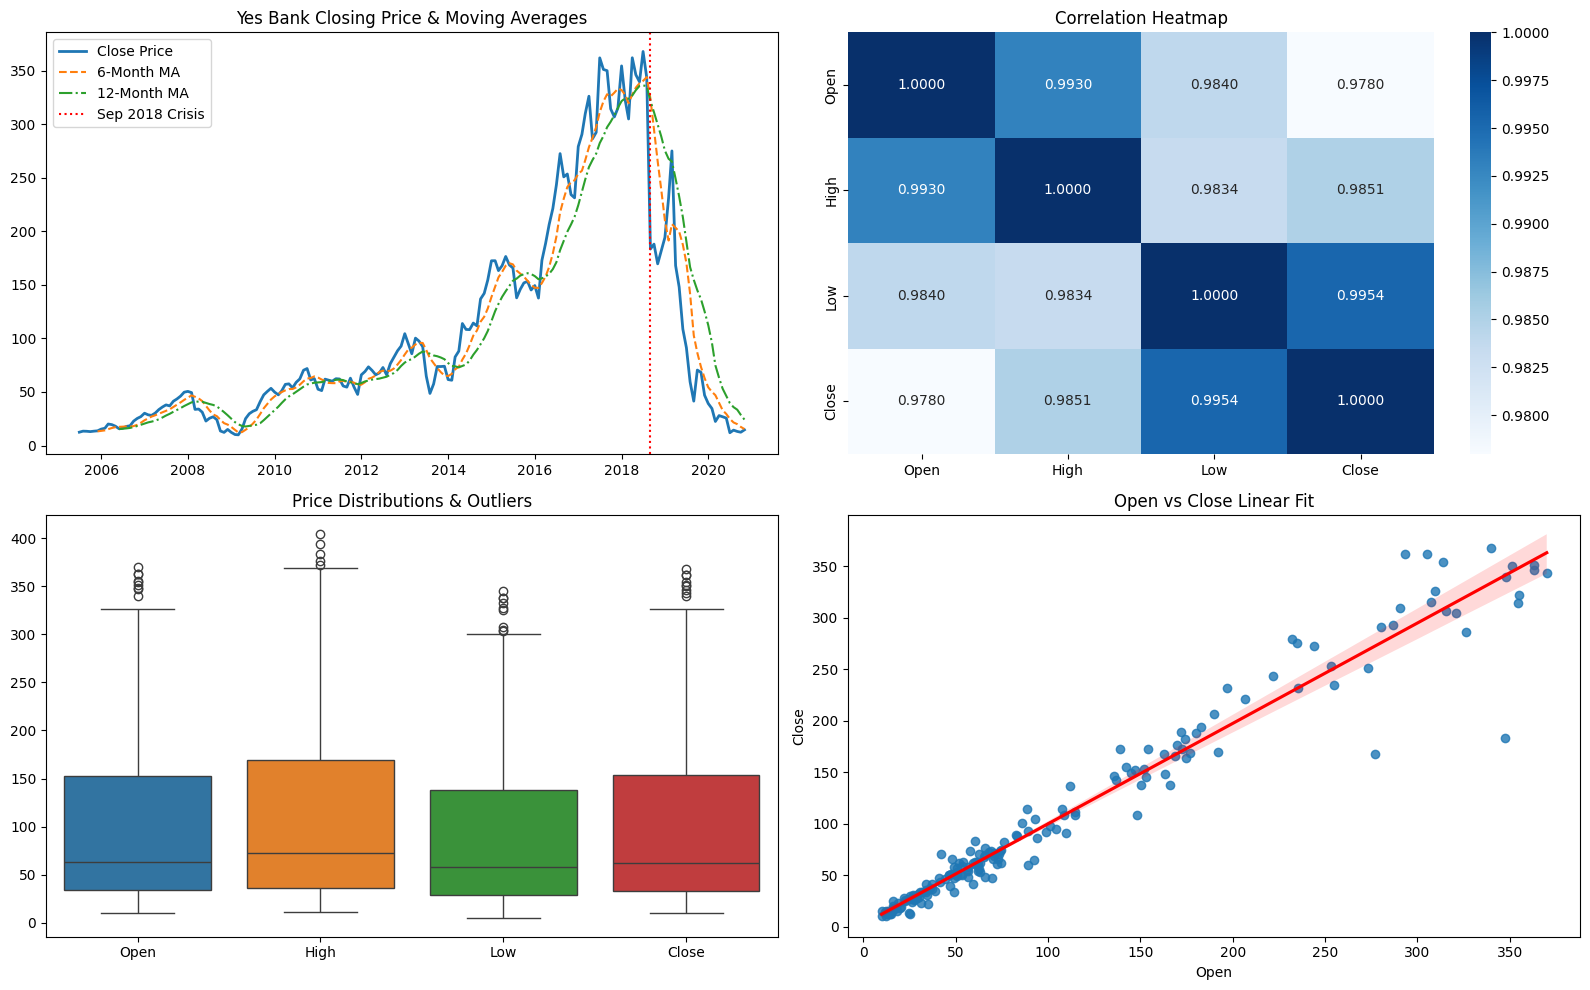

            Model                                                 Best Params      MSE    RMSE     MAE  MAPE (%)     R2
       ElasticNet                           {'alpha': 0.001, 'l1_ratio': 0.9} 249.1150 15.7834  9.8631     11.94 0.9848
            Lasso                                            {'alpha': 0.001} 249.9850 15.8109  9.7925     11.88 0.9848
            Ridge                                            {'alpha': 0.001} 250.2520 15.8194  9.7891     11.88 0.9848
Linear Regression                                                     Default 250.3307 15.8218  9.7843     11.88 0.9848
    Random Forest                       {'max_depth': 5, 'n_estimators': 200} 472.2991 21.7324 14.0603     16.25 0.9712
Gradient Boosting {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100} 595.3121 24.3990 13.5593     14.90 0.9637


In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Suppress non-critical convergence/plotting warnings to keep notebook output clean and readable
warnings.filterwarnings('ignore')

# Use raw.githubusercontent.com rather than /blob/ so pandas can directly stream the raw CSV file
GITHUB_CSV_URL = (
    'https://raw.githubusercontent.com/SristiSarkarMCKV/'
    'Yes-Bank-Stock-Closing-Price-Prediction/main/data_YesBank_StockPrices.csv'
)



# 1. DATA LOADING & CLEAN-UP
# Requirement: Load the monthly OHLC dataset, verify no missing/corrupted rows
# exist, and sort chronologically so time-ordered operations are valid.

def load_and_clean_data(filepath_or_url: str) -> pd.DataFrame:
  # Read CSV directly from the raw GitHub URL
  df = pd.read_csv(filepath_or_url)

  # Parse 'Mon-YY' strings into true datetime objects for accurate time sorting and plotting
  df['Date_dt'] = pd.to_datetime(df['Date'], format='%b-%y')

  # Sort chronologically from earliest to latest month and reset row indices
  df = df.sort_values('Date_dt').reset_index(drop=True)

  # Fail-fast check to ensure data integrity (no missing/null values) before modeling
  assert df.isnull().sum().sum() == 0, 'Missing values detected!'
  return df



# 2. EXPLORATORY DATA ANALYSIS (EDA) & MULTICOLLINEARITY CHECK
# Requirement: Understand price trends (including the 2018 crisis), check
# correlations among dependent/independent variables, inspect outliers, and
# diagnose multicollinearity (VIF) across OHLC features.

def run_eda(df: pd.DataFrame):
  # Compute rolling moving averages to smooth short-term noise and highlight medium/long-term trends
  df['MA_6'] = df['Close'].rolling(window=6).mean()
  df['MA_12'] = df['Close'].rolling(window=12).mean()

  # Calculate Variance Inflation Factor (VIF) to quantify multicollinearity among Open, High, and Low
  # High VIF (>10) indicates strong collinearity, motivating regularized regression (Ridge/Lasso/ElasticNet)
  X_vif = df[['Open', 'High', 'Low']]
  vif_df = pd.DataFrame({
      'Feature': X_vif.columns,
      'VIF': [
          variance_inflation_factor(X_vif.values, i)
          for i in range(X_vif.shape[1])
      ],
  })
  print('Variance Inflation Factors:\n', vif_df, '\n')

  # Create a 2x2 visual dashboard covering trend, correlation, outliers, and linear fit
  fig, axes = plt.subplots(2, 2, figsize=(16, 10))

  # Top-left: Closing price trajectory with moving averages and Sep 2018 crisis marker
  axes[0, 0].plot(df['Date_dt'], df['Close'], label='Close Price', linewidth=2)
  axes[0, 0].plot(
      df['Date_dt'], df['MA_6'], label='6-Month MA', linestyle='--'
  )
  axes[0, 0].plot(
      df['Date_dt'], df['MA_12'], label='12-Month MA', linestyle='-.'
  )
  axes[0, 0].axvline(
      pd.to_datetime('2018-09-01'),
      color='red',
      linestyle=':',
      label='Sep 2018 Crisis',
  )
  axes[0, 0].set_title('Yes Bank Closing Price & Moving Averages')
  axes[0, 0].legend()

  # Top-right: Correlation heatmap to inspect relationships between features and target ('Close')
  sns.heatmap(
      df[['Open', 'High', 'Low', 'Close']].corr(),
      annot=True,
      cmap='Blues',
      fmt='.4f',
      ax=axes[0, 1],
  )
  axes[0, 1].set_title('Correlation Heatmap')

  # Bottom-left: Boxplots to inspect spread and extreme values (retained because they reflect real market peaks)
  sns.boxplot(data=df[['Open', 'High', 'Low', 'Close']], ax=axes[1, 0])
  axes[1, 0].set_title('Price Distributions & Outliers')

  # Bottom-right: Scatter + regression line to verify linear relationship between Open and Close
  sns.regplot(
      x='Open', y='Close', data=df, ax=axes[1, 1], line_kws={'color': 'red'}
  )
  axes[1, 1].set_title('Open vs Close Linear Fit')

  plt.tight_layout()
  plt.show()



# 3. PREPROCESSING & CHRONOLOGICAL TRAIN-TEST SPLIT
# Requirement: Select appropriate independent features, split chronologically to
# prevent future data leakage, and standardize features on training data only.

def prepare_data(df: pd.DataFrame, split_ratio: float = 0.80):
  # Select monthly Open, High, and Low as predictors for the target Close price
  features = ['Open', 'High', 'Low']
  X, y = df[features], df['Close']

  # Use a chronological split (rather than random shuffle) to test out-of-time generalization
  split_idx = int(len(df) * split_ratio)

  X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
  y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
  dates_test = df['Date_dt'].iloc[split_idx:]

  # Fit StandardScaler strictly on X_train so test statistics do not leak into training
  # Scaling also ensures fair regularization penalties across features
  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  return X_train_scaled, X_test_scaled, y_train, y_test, dates_test, features



# 4. MODEL TRAINING, HYPERPARAMETER TUNING & EVALUATION
# Requirement: Experiment with multiple regression models, tune hyperparameters
# using time-aware cross-validation, and evaluate with standard error/fit metrics.

def train_and_evaluate(X_train, X_test, y_train, y_test):
  # Use TimeSeriesSplit so validation folds always precede training folds chronologically
  tscv = TimeSeriesSplit(n_splits=5)

  # Define baseline linear, regularized linear (for collinearity/overfitting), and tree ensemble models
  model_configs = {
      'Linear Regression': (LinearRegression(), {}),
      'Ridge': (Ridge(), {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]}),
      'Lasso': (
          Lasso(max_iter=10000),
          {'alpha': [0.001, 0.01, 0.1, 1.0, 10.0]},
      ),
      'ElasticNet': (
          ElasticNet(max_iter=10000),
          {'alpha': [0.001, 0.01, 0.1, 1.0], 'l1_ratio': [0.1, 0.5, 0.9]},
      ),
      'Random Forest': (
          RandomForestRegressor(random_state=42),
          {'n_estimators': [100, 200], 'max_depth': [None, 5, 10]},
      ),
      'Gradient Boosting': (
          GradientBoostingRegressor(random_state=42),
          {
              'n_estimators': [100, 200],
              'learning_rate': [0.05, 0.1],
              'max_depth': [3, 5],
          },
      ),
  }

  results, trained_models = [], {}

  for name, (model, params) in model_configs.items():
    if params:
      # Tune hyperparameters via GridSearchCV using negative MSE as the selection metric
      grid = GridSearchCV(
          model, params, cv=tscv, scoring='neg_mean_squared_error'
      )
      grid.fit(X_train, y_train)
      best_model = grid.best_estimator_
      best_params = grid.best_params_
    else:
      # Fit unregularized baseline model directly
      best_model = model.fit(X_train, y_train)
      best_params = 'Default'

    trained_models[name] = best_model

    # Generate out-of-sample predictions on the held-out test set
    preds = best_model.predict(X_test)

    # Record MSE, RMSE, MAE, MAPE, and R² to compare accuracy and explained variance
    mse = mean_squared_error(y_test, preds)
    results.append({
        'Model': name,
        'Best Params': str(best_params),
        'MSE': round(mse, 4),
        'RMSE': round(np.sqrt(mse), 4),
        'MAE': round(mean_absolute_error(y_test, preds), 4),
        'MAPE (%)': round(
            mean_absolute_percentage_error(y_test, preds) * 100, 2
        ),
        'R2': round(r2_score(y_test, preds), 4),
    })

  # Rank models from lowest to highest RMSE so the strongest predictor appears first
  results_df = pd.DataFrame(results).sort_values(by='RMSE')
  print(results_df.to_string(index=False))
  return trained_models, results_df


# 5. END-TO-END PIPELINE EXECUTION
# Requirement: Run the modular steps sequentially to produce EDA, metrics, and models.

df = load_and_clean_data(GITHUB_CSV_URL)
run_eda(df)
X_train, X_test, y_train, y_test, dates_test, feat_names = prepare_data(df)
models, summary_table = train_and_evaluate(X_train, X_test, y_train, y_test)